In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

In [2]:
df = pd.read_csv("real_estate_final.csv")

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print(df["Good_Investment"].value_counts())
print(df["Good_Investment"].value_counts(normalize=True).round(3))

Dataset Shape: (250000, 93)
Missing Values: 0
Good_Investment
1    240918
0      9082
Name: count, dtype: int64
Good_Investment
1    0.964
0    0.036
Name: proportion, dtype: float64


In [3]:
target = "Good_Investment"

X = df.drop(
    columns=["Good_Investment", "Investment_Score", "Future_Price_5Y", "ID"],
    errors="ignore"
)
y = df[target]

print("X Shape:", X.shape, "| y Shape:", y.shape)

X Shape: (250000, 90) | y Shape: (250000,)


In [4]:
# stratify keeps the Yes/No ratio identical in train and test (data is imbalanced)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (200000, 90) | X_test: (50000, 90)


In [5]:
numeric_features = [
    col for col in [
        "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt",
        "Year_Built", "Floor_No", "Total_Floors", "Age_of_Property",
        "Nearby_Schools", "Nearby_Hospitals", "Amenity_Density_Score",
        "Locality_Frequency"
    ]
    if col in X_train.columns
]

X_train = X_train.copy()
X_test = X_test.copy()
X_train[numeric_features] = X_train[numeric_features].astype(float)
X_test[numeric_features] = X_test[numeric_features].astype(float)

# Fit the scaler on TRAIN only, then apply to test (no leakage)
scaler = StandardScaler()
X_train[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

print("Scaled", len(numeric_features), "numeric features.")

Scaled 12 numeric features.


In [7]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", random_state=42, max_iter=1000
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=15, class_weight="balanced_subsample",
        random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        scale_pos_weight=neg / pos, eval_metric="logloss",
        random_state=42, n_jobs=-1
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.
Gradient Boosting trained.
XGBoost trained.


In [8]:
results, predictions, probabilities = [], {}, {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name], probabilities[name] = y_pred, y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
    })

results_df = (
    pd.DataFrame(results)
    .sort_values(by=["F1", "ROC_AUC"], ascending=False)
    .reset_index(drop=True)
)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost,0.99998,1.000000,0.999979,0.999990,1.000000
1,Decision Tree,0.99996,0.999958,1.000000,0.999979,0.999449
2,Gradient Boosting,0.99994,0.999938,1.000000,0.999969,1.000000
3,Random Forest,0.99826,0.999170,0.999025,0.999097,0.999697
4,Logistic Regression,0.93736,0.998672,0.936244,0.966451,0.987322


In [9]:
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

print("Best model (by F1, then ROC-AUC):", best_model_name)
print()
print(classification_report(
    y_test, predictions[best_model_name],
    target_names=["Not Good", "Good Investment"]
))

Best model (by F1, then ROC-AUC): XGBoost

                 precision    recall  f1-score   support

       Not Good       1.00      1.00      1.00      1816
Good Investment       1.00      1.00      1.00     48184

       accuracy                           1.00     50000
      macro avg       1.00      1.00      1.00     50000
   weighted avg       1.00      1.00      1.00     50000



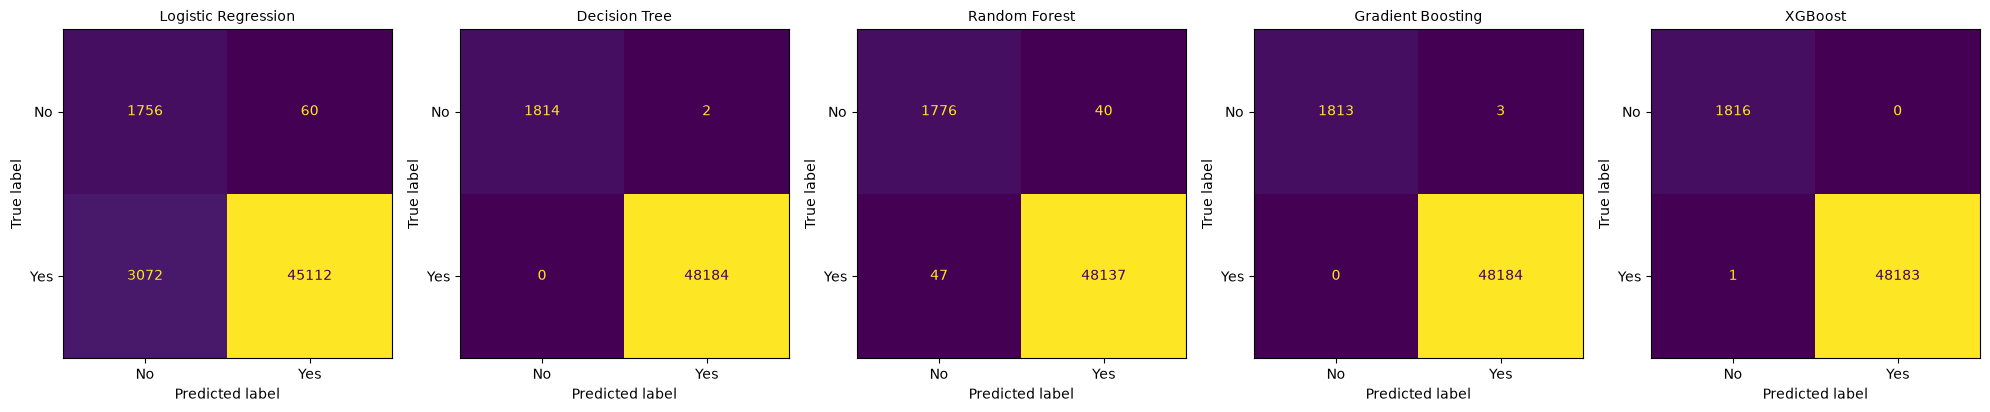

In [10]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, y_pred),
        display_labels=["No", "Yes"]
    ).plot(ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)

plt.tight_layout()
plt.show()

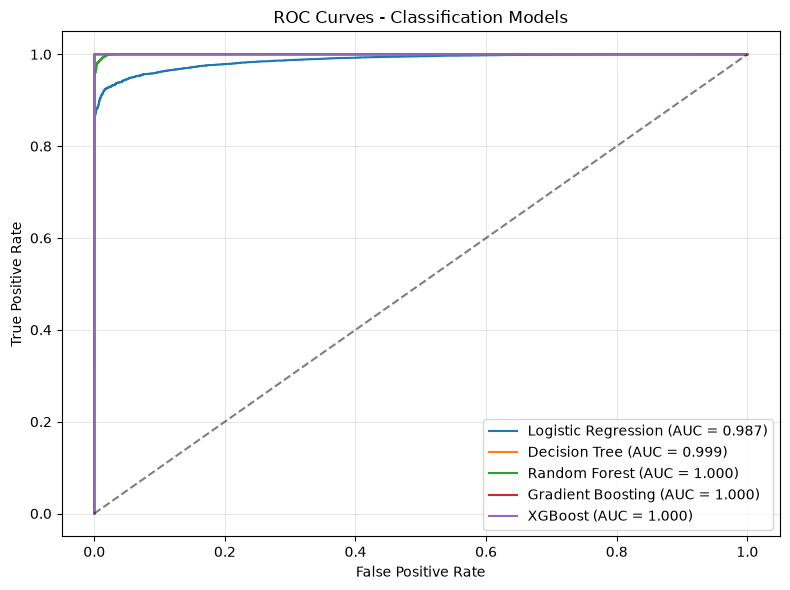

In [11]:
plt.figure(figsize=(8, 6))

for name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Classification Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

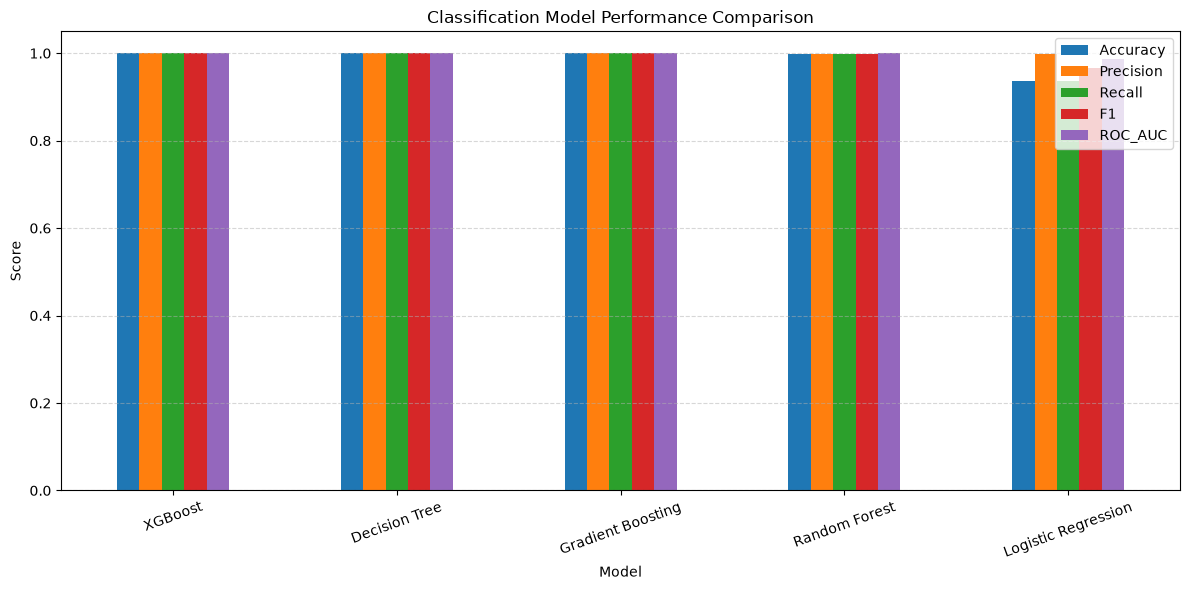

In [12]:
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1.05)
)
plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

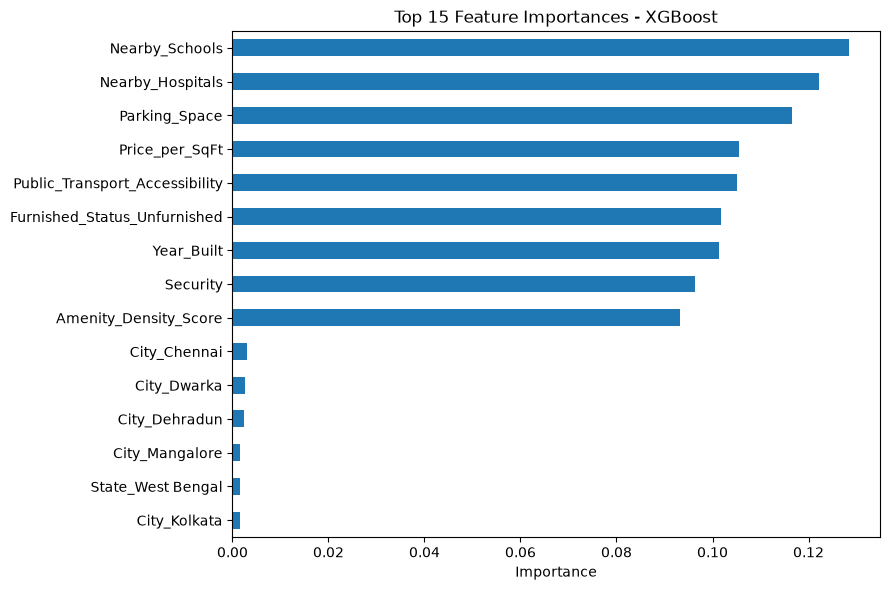

In [13]:
# Feature importance of the best tree-based model
tree_models = {k: v for k, v in models.items() if hasattr(v, "feature_importances_")}
top_name = max(tree_models, key=lambda k: results_df.set_index("Model").loc[k, "F1"])

importance = (
    pd.Series(tree_models[top_name].feature_importances_, index=X_train.columns)
    .sort_values(ascending=False)
    .head(15)
)

importance[::-1].plot(kind="barh", figsize=(9, 6))
plt.title(f"Top 15 Feature Importances - {top_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [14]:
SAVE_DIR = "saved_models/classification"
os.makedirs(SAVE_DIR, exist_ok=True)

for name, model in models.items():
    filename = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(model, f"{SAVE_DIR}/{filename}")

# Preprocessing artifacts used by app.py
joblib.dump(scaler, f"{SAVE_DIR}/scaler.pkl")
joblib.dump(numeric_features, f"{SAVE_DIR}/numeric_features.pkl")
joblib.dump(X_train.columns.tolist(), f"{SAVE_DIR}/feature_columns.pkl")
results_df.to_csv(f"{SAVE_DIR}/metrics.csv", index=False)

print("Saved files:", sorted(os.listdir(SAVE_DIR)))

Saved files: ['decision_tree.pkl', 'feature_columns.pkl', 'gradient_boosting.pkl', 'logistic_regression.pkl', 'metrics.csv', 'numeric_features.pkl', 'random_forest.pkl', 'scaler.pkl', 'xgboost.pkl']
